In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models
from tensorflow.keras.datasets import cifar10


(x_train, y_train), (x_test, y_test) = cifar10.load_data()
class_names = ["airplane", "automobile", "bird", "cat", "deer",
               "dog", "frog", "horse", "ship", "truck"]

# Use a subset to make the practical faster on Colab
x_train, y_train = x_train[:10000], y_train[:10000].flatten()
x_test, y_test = x_test[:2000], y_test[:2000].flatten()

print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)

TensorFlow version: 2.21.0
170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 2137s 13us/step
Training data: (10000, 32, 32, 3)
Testing data: (2000, 32, 32, 3)


In [2]:
# MobileNetV2 has pre-trained ImageNet weights.
# The original classification head is removed.
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(96, 96, 3),
    include_top=False,
    weights="imagenet"
)
base_model.trainable = False
print("Pre-trained MobileNetV2 loaded; all base layers frozen.")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Pre-trained MobileNetV2 loaded; all base layers frozen.


In [3]:
inputs = layers.Input(shape=(32, 32, 3), name="input_image")
x = layers.RandomFlip("horizontal")(inputs)
x = layers.Resizing(96, 96)(x)

# MobileNetV2 preprocessing expects input pixels scaled to approximately [-1, 1]
x = tf.keras.applications.mobilenet_v2.preprocess_input(x)
features = base_model(x, training=False)

x = layers.GlobalAveragePooling2D()(features)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(10, activation="softmax")(x)

model = models.Model(inputs, outputs, name="TransferLearningModel")
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
model.summary()

Model: "TransferLearningModel"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resizing (Resizing)             │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_96             │ (None, 3, 3, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,423,242 (9.24 MB)

 Trainable params: 165,258 (645.54 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [4]:
history_initial = model.fit(
    x_train, y_train,
    validation_split=0.2,
    epochs=5,
    batch_size=32,
    verbose=1
)

Epoch 1/5
250/250 ━━━━━━━━━━━━━━━━━━━━ 40s 146ms/step - accuracy: 0.7280 - loss: 0.8086 - val_accuracy: 0.8260 - val_loss: 0.5223
Epoch 2/5
250/250 ━━━━━━━━━━━━━━━━━━━━ 40s 144ms/step - accuracy: 0.8284 - loss: 0.4997 - val_accuracy: 0.8385 - val_loss: 0.4818
Epoch 3/5
250/250 ━━━━━━━━━━━━━━━━━━━━ 44s 158ms/step - accuracy: 0.8596 - loss: 0.4109 - val_accuracy: 0.8425 - val_loss: 0.4667
Epoch 4/5
250/250 ━━━━━━━━━━━━━━━━━━━━ 36s 144ms/step - accuracy: 0.8766 - loss: 0.3468 - val_accuracy: 0.8435 - val_loss: 0.4825
Epoch 5/5
250/250 ━━━━━━━━━━━━━━━━━━━━ 42s 147ms/step - accuracy: 0.8936 - loss: 0.2975 - val_accuracy: 0.8390 - val_loss: 0.5201


In [5]:
# Unfreeze the top 20% of MobileNetV2 layers; keep earlier layers frozen
base_model.trainable = True
fine_tune_at = int(len(base_model.layers) * 0.8)

for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

# Keep Batch Normalization layers frozen for stable fine-tuning
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

# Recompile with a much smaller learning rate for fine-tuning
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_fine = model.fit(
    x_train, y_train,
    validation_split=0.2,
    epochs=3,
    batch_size=32,
    verbose=1
)

Epoch 1/3
250/250 ━━━━━━━━━━━━━━━━━━━━ 63s 234ms/step - accuracy: 0.9206 - loss: 0.2257 - val_accuracy: 0.8670 - val_loss: 0.4668
Epoch 2/3
250/250 ━━━━━━━━━━━━━━━━━━━━ 60s 242ms/step - accuracy: 0.9386 - loss: 0.1815 - val_accuracy: 0.8595 - val_loss: 0.4652
Epoch 3/3
250/250 ━━━━━━━━━━━━━━━━━━━━ 78s 225ms/step - accuracy: 0.9470 - loss: 0.1591 - val_accuracy: 0.8720 - val_loss: 0.4603


Test loss: 0.4286
Test accuracy: 86.50%


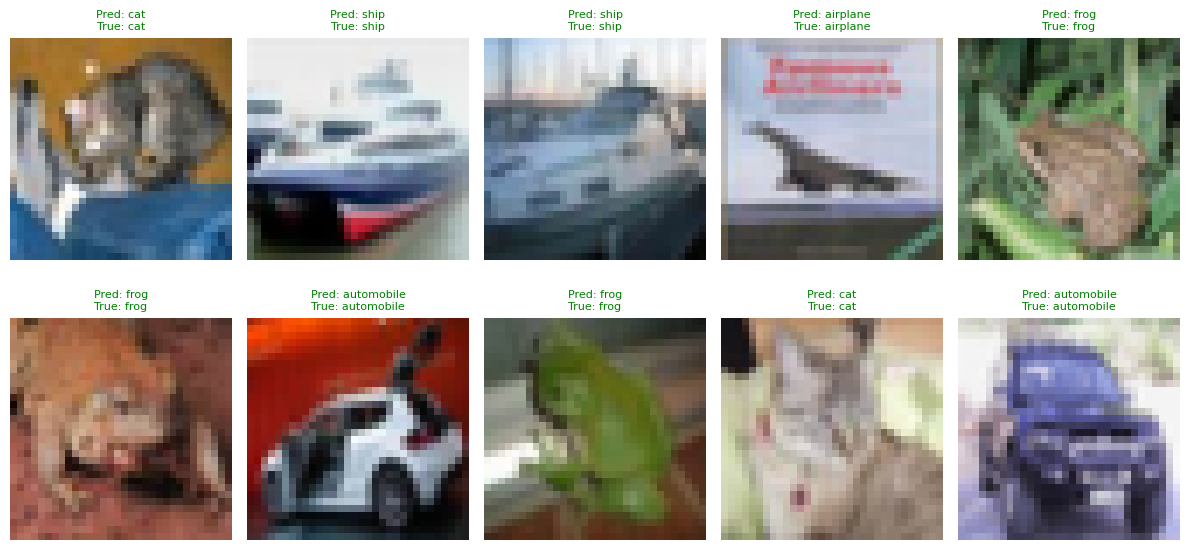

In [6]:
test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=0)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy * 100:.2f}%")

probabilities = model.predict(x_test[:10], verbose=0)
predicted_labels = np.argmax(probabilities, axis=1)

plt.figure(figsize=(12, 6))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i])
    color = "green" if predicted_labels[i] == y_test[i] else "red"
    plt.title(f"Pred: {class_names[predicted_labels[i]]}\nTrue: {class_names[y_test[i]]}",
              color=color, fontsize=8)
    plt.axis("off")
plt.tight_layout()
plt.show()

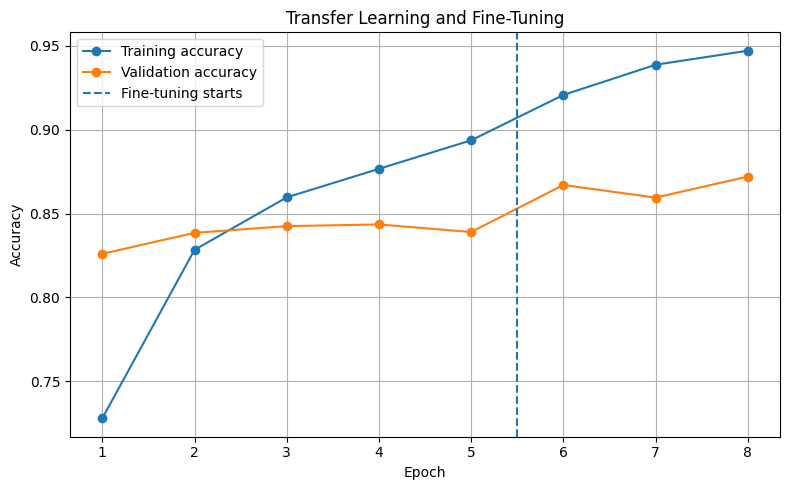

In [7]:
train_acc = history_initial.history["accuracy"] + history_fine.history["accuracy"]
val_acc = history_initial.history["val_accuracy"] + history_fine.history["val_accuracy"]

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(train_acc) + 1), train_acc, marker="o", label="Training accuracy")
plt.plot(range(1, len(val_acc) + 1), val_acc, marker="o", label="Validation accuracy")
plt.axvline(len(history_initial.history["accuracy"]) + 0.5, linestyle="--",
            label="Fine-tuning starts")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Transfer Learning and Fine-Tuning")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()